# Uczenie maszynowe – klasyfikacja

## Zadania do wykonania

- [x] Zaimportować biblioteki: `pandas`, `numpy`, `seaborn` oraz `matplotlib.pyplot` jako `plt`.
- [x] Wczytać dataset `dataSets/pulsar_stars.csv` do DataFrame'a `df`.
- [x] Sprawdzić rozmiar (wymiary) DataFrame'a `df`.
- [x] Zapoznać się ze strukturą `df` za pomocą metody `head()`.
- [x] Zmienić długie nazwy kolumn na krótsze i czytelne.
- [x] Usunąć białe znaki z początku nazw kolumn.
- [x] Sprawdzić rozkład wartości atrybutu `target_class`.
- [x] Sprawdzić, czy w DataFrame'ie występują wartości puste.
- [x] Obliczyć statystyki opisowe za pomocą metody `describe()`.
- [x] Zwizualizować wartości odstające za pomocą wykresów pudełkowych (`boxplot`).
- [x] Wygenerować histogram dla każdej kolumny.
- [x] Podzielić dane na cechy `X` i przewidywany atrybut `y`.
- [x] Podzielić dane na zbiór treningowy i testowy.
- [x] Przeskalować cechy za pomocą `StandardScaler`.
- [x] Dopasować domyślny model `SVC` i obliczyć `accuracy_score`.
- [x] Sprawdzić model `SVC` z `C=100`.
- [x] Porównać wynik treningowy i testowy dla `SVC(kernel="linear")`.
- [x] Porównać modele `SVC` z `kernel="poly"` i `kernel="sigmoid"`.
- [x] Wyświetlić macierz pomyłek i zwizualizować ją na heatmapie.
- [x] Zoptymalizować hiperparametry za pomocą `GridSearchCV`.

### Import bibliotek
Importujemy biblioteki do pracy z danymi (`pandas`, `numpy`), wizualizacji (`seaborn`, `matplotlib`) oraz tworzymy ich krótkie aliasy.

In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.pipeline import make_pipeline

### Wczytanie danych
Odczytujemy plik CSV z danymi pulsarów do obiektu `df` typu DataFrame.

In [18]:
df = pd.read_csv("dataSets/pulsar_stars.csv")

### Wymiary zbioru danych
Wyświetlamy liczbę wierszy i kolumn DataFrame'a, aby sprawdzić rozmiar wczytanego zbioru.

In [19]:
print(f"Wymiary DataFrame'a: {df.shape}")

Wymiary DataFrame'a: (17898, 9)


### Podgląd danych
Wyświetlamy pierwsze pięć wierszy, aby zapoznać się z zawartością i układem kolumn.

In [20]:
df.head()

,Mean of the integrated profile,Standard deviation of the integrated profile,Excess kurtosis of the integrated profile,Skewness of the integrated profile,Mean of the DM-SNR curve,Standard deviation of the DM-SNR curve,Excess kurtosis of the DM-SNR curve,Skewness of the DM-SNR curve,target_class
0,140.562500,55.683782,-0.234571,-0.699648,3.199833,19.110426,7.975532,74.242225,0
1,102.507812,58.882430,0.465318,-0.515088,1.677258,14.860146,10.576487,127.393580,0
2,103.015625,39.341649,0.323328,1.051164,3.121237,21.744669,7.735822,63.171909,0
3,136.750000,57.178449,-0.068415,-0.636238,3.642977,20.959280,6.896499,53.593661,0
4,88.726562,40.672225,0.600866,1.123492,1.178930,11.468720,14.269573,252.567306,0


### Czyszczenie i skracanie nazw kolumn
Usuwamy białe znaki z początku i końca nazw, a następnie zastępujemy długie nazwy krótszymi i czytelniejszymi.

In [21]:
df.columns = df.columns.str.strip()

df = df.rename(columns={
    "Mean of the integrated profile": "mean_profile",
    "Standard deviation of the integrated profile": "std_profile",
    "Excess kurtosis of the integrated profile": "kurtosis_profile",
    "Skewness of the integrated profile": "skewness_profile",
    "Mean of the DM-SNR curve": "mean_dm_snr",
    "Standard deviation of the DM-SNR curve": "std_dm_snr",
    "Excess kurtosis of the DM-SNR curve": "kurtosis_dm_snr",
    "Skewness of the DM-SNR curve": "skewness_dm_snr",
    "target_class": "target_class",
})

df.head()

,mean_profile,std_profile,kurtosis_profile,skewness_profile,mean_dm_snr,std_dm_snr,kurtosis_dm_snr,skewness_dm_snr,target_class
0,140.562500,55.683782,-0.234571,-0.699648,3.199833,19.110426,7.975532,74.242225,0
1,102.507812,58.882430,0.465318,-0.515088,1.677258,14.860146,10.576487,127.393580,0
2,103.015625,39.341649,0.323328,1.051164,3.121237,21.744669,7.735822,63.171909,0
3,136.750000,57.178449,-0.068415,-0.636238,3.642977,20.959280,6.896499,53.593661,0
4,88.726562,40.672225,0.600866,1.123492,1.178930,11.468720,14.269573,252.567306,0


### Rozkład przewidywanej klasy
Liczymy wystąpienia każdej wartości w `target_class`, aby sprawdzić liczebność obu klas.

In [22]:
df["target_class"].value_counts().sort_index()

target_class
0    16259
1     1639
Name: count, dtype: int64

### Kontrola brakujących wartości
Sprawdzamy liczbę pustych wartości w każdej kolumnie oraz informację, czy braki występują w całym zbiorze.

In [23]:
missing_values = df.isna().sum()
print(f"Czy występują wartości puste: {df.isna().values.any()}")
missing_values

Czy występują wartości puste: False


mean_profile        0
std_profile         0
kurtosis_profile    0
skewness_profile    0
mean_dm_snr         0
std_dm_snr          0
kurtosis_dm_snr     0
skewness_dm_snr     0
target_class        0
dtype: int64

### Statystyki opisowe
Obliczamy podstawowe statystyki numeryczne, takie jak średnia, odchylenie standardowe, kwartyle oraz wartości skrajne.

In [24]:
df.describe()

,mean_profile,std_profile,kurtosis_profile,skewness_profile,mean_dm_snr,std_dm_snr,kurtosis_dm_snr,skewness_dm_snr,target_class
count,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000
mean,111.079968,46.549532,0.477857,1.770279,12.614400,26.326515,8.303556,104.857709,0.091574
std,25.652935,6.843189,1.064040,6.167913,29.472897,19.470572,4.506092,106.514540,0.288432
min,5.812500,24.772042,-1.876011,-1.791886,0.213211,7.370432,-3.139270,-1.976976,0.000000
25%,100.929688,42.376018,0.027098,-0.188572,1.923077,14.437332,5.781506,34.960504,0.000000
50%,115.078125,46.947479,0.223240,0.198710,2.801839,18.461316,8.433515,83.064556,0.000000
75%,127.085938,51.023202,0.473325,0.927783,5.464256,28.428104,10.702959,139.309330,0.000000
max,192.617188,98.778911,8.069522,68.101622,223.392141,110.642211,34.539844,1191.000837,1.000000


### Wizualizacja wartości odstających
Tworzymy wykres pudełkowy dla każdej cechy (bez kolumny docelowej), aby porównać rozkłady i zauważyć potencjalne wartości odstające.

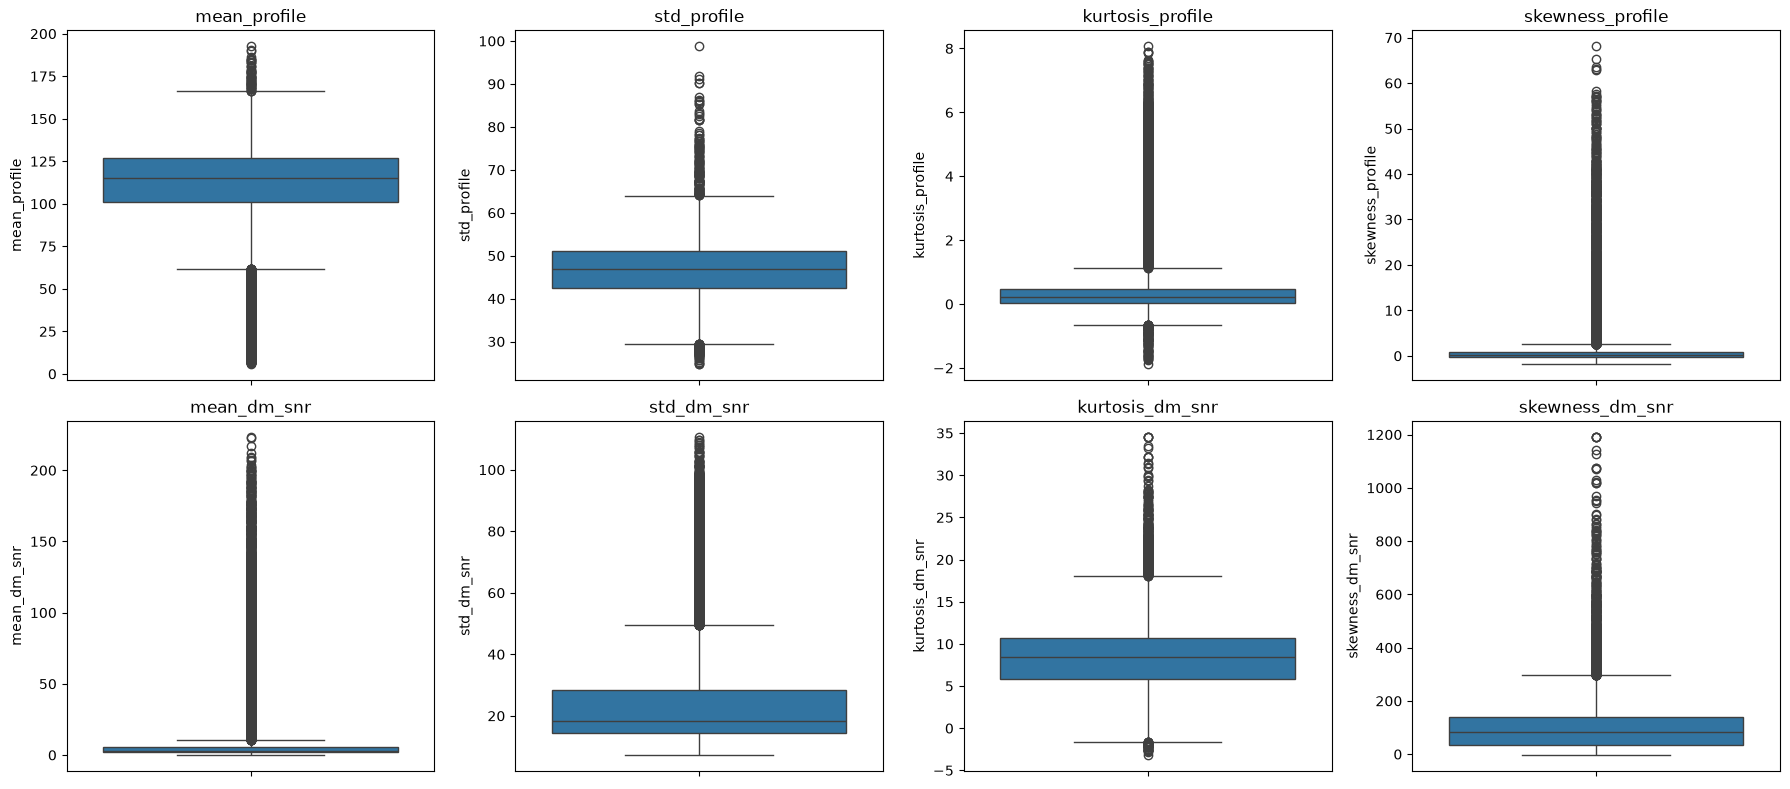

In [25]:
feature_columns = df.columns.drop("target_class")
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, column in zip(axes.flat, feature_columns):
    sns.boxplot(y=df[column], ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

### Histogramy kolumn
Generujemy histogramy dla wszystkich kolumn numerycznych, aby obejrzeć rozkład wartości każdej zmiennej.

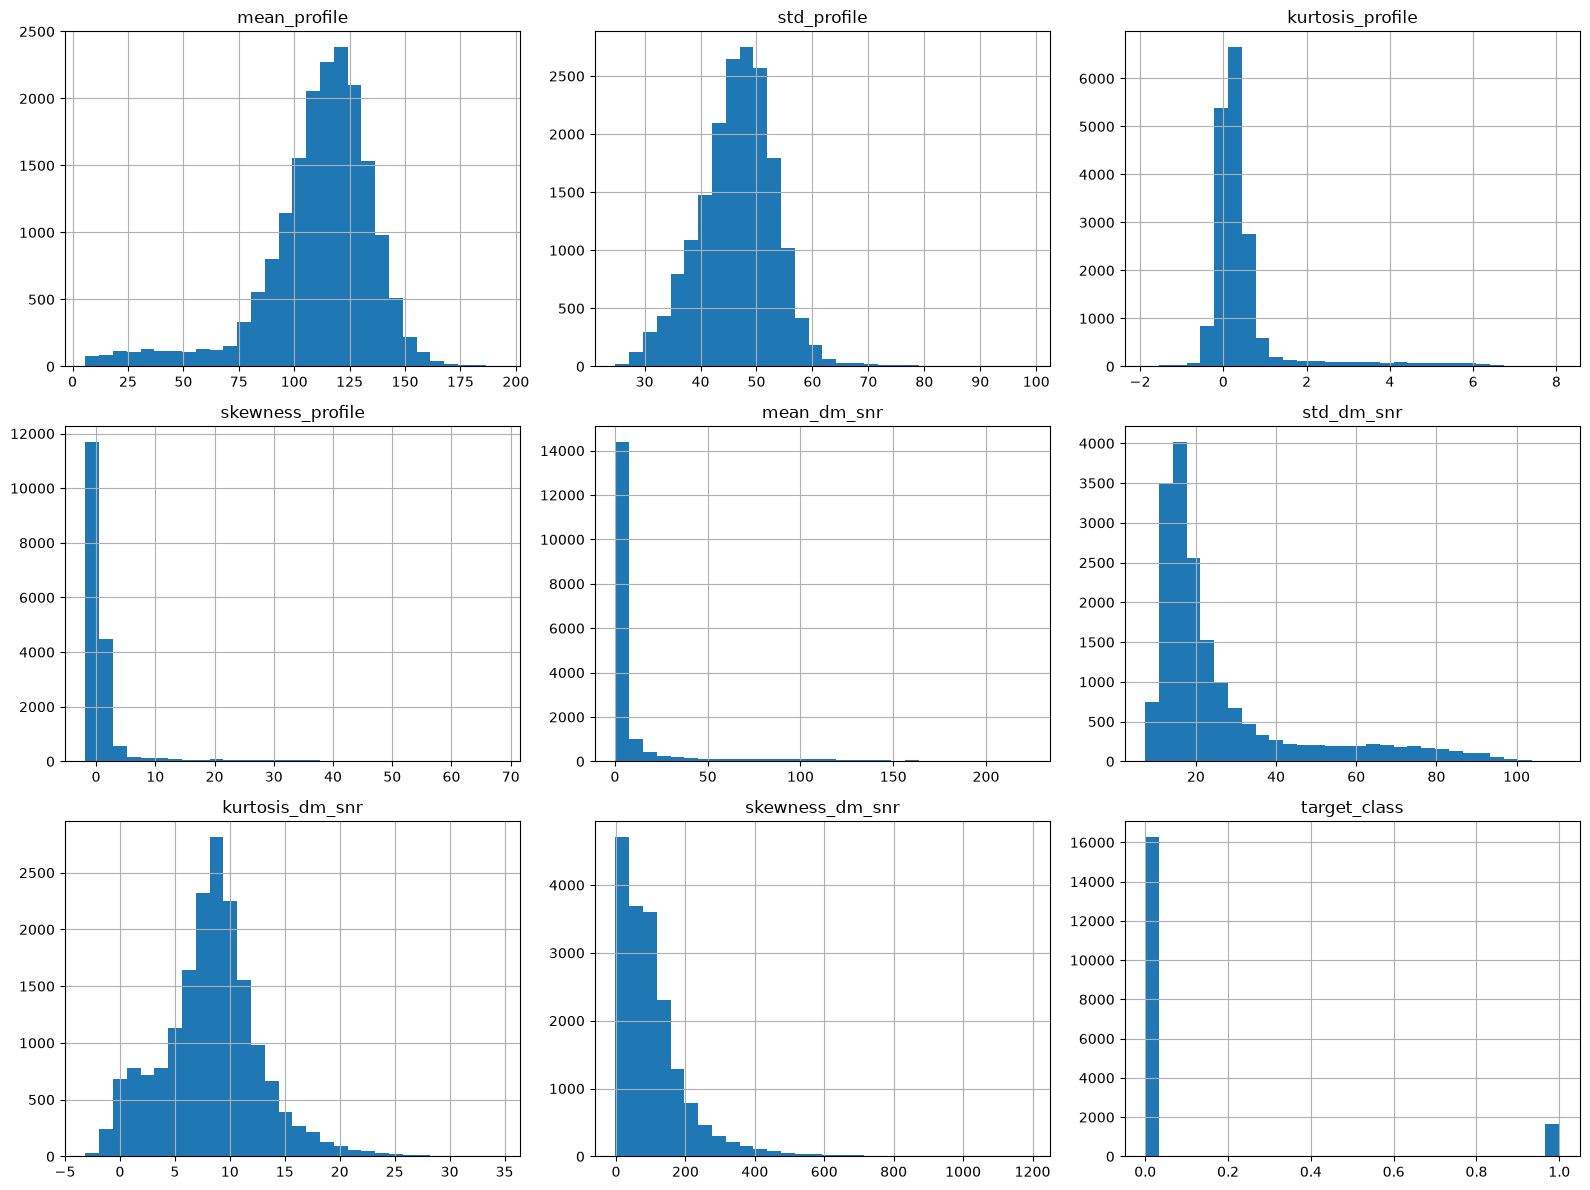

In [26]:
df.hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()

### Podział na cechy i atrybut docelowy
Tworzymy `X` z cech używanych do przewidywania oraz `y` z wartościami docelowymi zapisanymi w `target_class`.

In [27]:
X = df.drop(columns="target_class")
y = df["target_class"]

print(f"Kształt X: {X.shape}")
print(f"Kształt y: {y.shape}")

Kształt X: (17898, 8)
Kształt y: (17898,)


### Podział na zbiory treningowy i testowy
Dzielimy cechy i etykiety w proporcji 80/20. Stratify zachowuje proporcje klas w obu zbiorach, a stałe ziarno losowe zapewnia powtarzalność wyniku.

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Rozmiar zbioru treningowego: {X_train.shape[0]}")
print(f"Rozmiar zbioru testowego: {X_test.shape[0]}")

Rozmiar zbioru treningowego: 14318
Rozmiar zbioru testowego: 3580


### Skalowanie cech
Dopasowujemy `StandardScaler` wyłącznie do cech treningowych, a następnie transformujemy oba zbiory tym samym skalowaniem, aby uniknąć wycieku informacji z testu.

In [29]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Domyślny model SVC
Dopasowujemy `SVC` z domyślnymi parametrami (w tym domyślnym jądrem RBF), przewidujemy etykiety dla testu i obliczamy accuracy.

In [30]:
svc = SVC()
svc.fit(X_train_scaled, y_train)
y_pred = svc.predict(X_test_scaled)
svc_accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy (SVC domyślny): {svc_accuracy:.4f}")

Accuracy (SVC domyślny): 0.9807


### SVC ze zwiększonym parametrem C
Trenujemy drugi model z `C=100` i porównujemy jego accuracy na tym samym zbiorze testowym.

In [31]:
svc_c100 = SVC(C=100)
svc_c100.fit(X_train_scaled, y_train)
y_pred_c100 = svc_c100.predict(X_test_scaled)
svc_c100_accuracy = accuracy_score(y_test, y_pred_c100)
print(f"Accuracy (SVC, C=100): {svc_c100_accuracy:.4f}")

Accuracy (SVC, C=100): 0.9813


### Porównanie wyniku treningowego i testowego dla jądra liniowego
Model `linear_svc` korzysta z klasy `SVC` z `kernel="linear"`. Metoda `score` zwraca accuracy osobno dla treningu i testu.

In [32]:
linear_svc = SVC(kernel="linear")
linear_svc.fit(X_train_scaled, y_train)

print(f"Accuracy na treningu: {linear_svc.score(X_train_scaled, y_train):.4f}")
print(f"Accuracy na teście: {linear_svc.score(X_test_scaled, y_test):.4f}")

Accuracy na treningu: 0.9788
Accuracy na teście: 0.9799


### Porównanie jąder poly i sigmoid
Trenujemy warianty `poly` i `sigmoid` z domyślnym `C` oraz `C=100`, a następnie zestawiamy ich accuracy na zbiorze testowym.

In [33]:
kernel_results = []

for kernel in ("poly", "sigmoid"):
    for c_value in (1, 100):
        model = SVC(kernel=kernel, C=c_value)
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)
        kernel_results.append({
            "kernel": kernel,
            "C": c_value,
            "accuracy": accuracy_score(y_test, predictions),
        })

pd.DataFrame(kernel_results)

,kernel,C,accuracy
0,poly,1,0.977933
1,poly,100,0.979888
2,sigmoid,1,0.877095
3,sigmoid,100,0.877374


### Macierz pomyłek
Obliczamy macierz pomyłek dla domyślnego modelu SVC; wiersze oznaczają klasy rzeczywiste, a kolumny przewidziane.

In [34]:
svc_confusion_matrix = confusion_matrix(y_test, y_pred)
svc_confusion_matrix

array([[3237,   15],
       [  54,  274]])

### Wizualizacja macierzy pomyłek
Przedstawiamy macierz pomyłek domyślnego modelu jako heatmapę z opisanymi klasami.

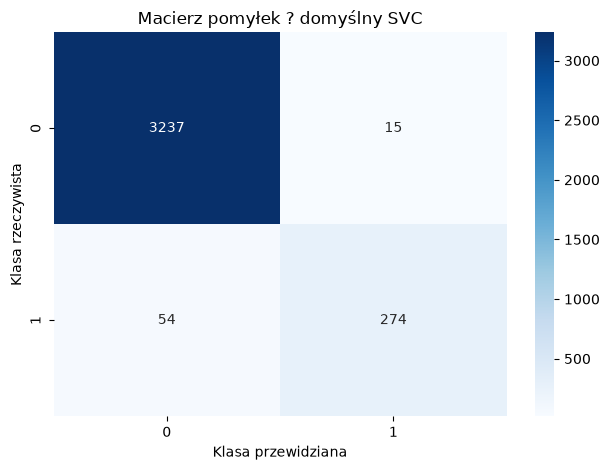

In [35]:
sns.heatmap(
    svc_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[0, 1],
    yticklabels=[0, 1],
)
plt.xlabel("Klasa przewidziana")
plt.ylabel("Klasa rzeczywista")
plt.title("Macierz pomyłek ? domyślny SVC")
plt.tight_layout()
plt.show()

### Optymalizacja hiperparametrów GridSearchCV
Przeszukujemy wybrane wartości `C` i jądra SVC, oceniając zbalansowaną trafność w 3-krotnej walidacji stratyfikowanej. Pipeline dopasowuje skalowanie osobno w każdym foldzie. Najlepszy model oceniamy na odłożonym zbiorze testowym.

In [36]:
svc_pipeline = make_pipeline(StandardScaler(), SVC())
parameter_grid = {
    "svc__kernel": ["linear", "rbf", "poly", "sigmoid"],
    "svc__C": [1, 100],
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    estimator=svc_pipeline,
    param_grid=parameter_grid,
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1,
    refit=True,
)
grid_search.fit(X_train, y_train)

print(f"Najlepsze parametry: {grid_search.best_params_}")
print(f"Najlepszy wynik balanced accuracy (CV): {grid_search.best_score_:.4f}")
print(f"Balanced accuracy na teście: {grid_search.score(X_test, y_test):.4f}")

Najlepsze parametry: {'svc__C': 100, 'svc__kernel': 'rbf'}
Najlepszy wynik balanced accuracy (CV): 0.9114
Balanced accuracy na teście: 0.9225
